<a href="https://colab.research.google.com/github/iceik973-dotcom/ML1/blob/main/Cards_CNN_VGG16_express.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Класифікація зображень гральних карт
Мета: порівняти власну CNN та VGG16 із донавчанням. [Набір даних Kaggle](https://www.kaggle.com/datasets/gpiosenka/cards-image-datasetclassification).

## 1. Завантаження даних

In [1]:
!pip -q install kagglehub
import kagglehub
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import time

tf.keras.utils.set_random_seed(42)
path = Path(kagglehub.dataset_download('gpiosenka/cards-image-datasetclassification'))
root = next(p for p in [path, *path.rglob('*')] if p.is_dir() and all((p / x).is_dir() for x in ['train', 'valid', 'test']))
print('Каталог:', root)

Using Colab cache for faster access to the 'cards-image-datasetclassification' dataset.
Каталог: /kaggle/input/cards-image-datasetclassification


## 2. Аналіз та візуалізація даних

,train,valid,test
ace of clubs,120,5,5
ace of diamonds,129,5,5
ace of hearts,171,5,5
ace of spades,181,5,5
eight of clubs,138,5,5
eight of diamonds,159,5,5
eight of hearts,152,5,5
eight of spades,135,5,5
five of clubs,150,5,5
five of diamonds,138,5,5


Кількість класів: 53
train    7624
valid     265
test      265
dtype: int64


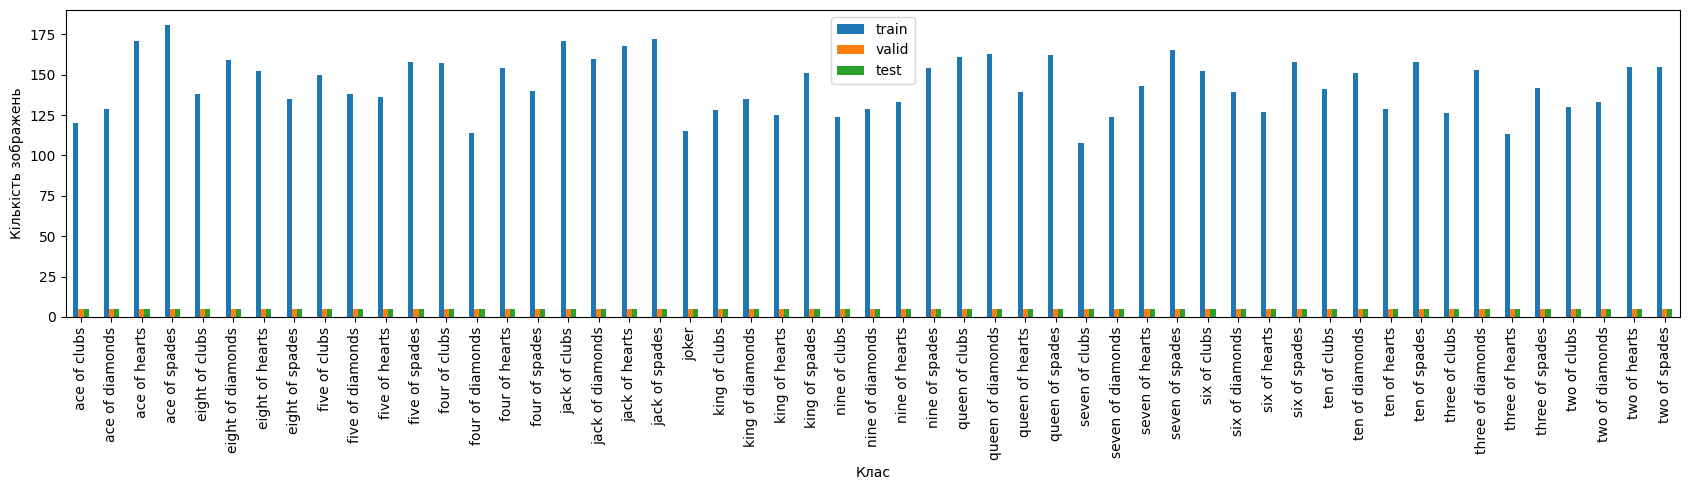

In [2]:
classes = sorted(p.name for p in (root/'train').iterdir() if p.is_dir())
extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.gif'}
counts = pd.DataFrame({split: [sum(f.suffix.lower() in extensions for f in (root/split/name).rglob('*')) for name in classes] for split in ['train','valid','test']}, index=classes)
display(counts)
print('Кількість класів:', len(classes))
print(counts.sum())
counts.plot(kind='bar', figsize=(17,5)); plt.xlabel('Клас'); plt.ylabel('Кількість зображень'); plt.tight_layout(); plt.show()

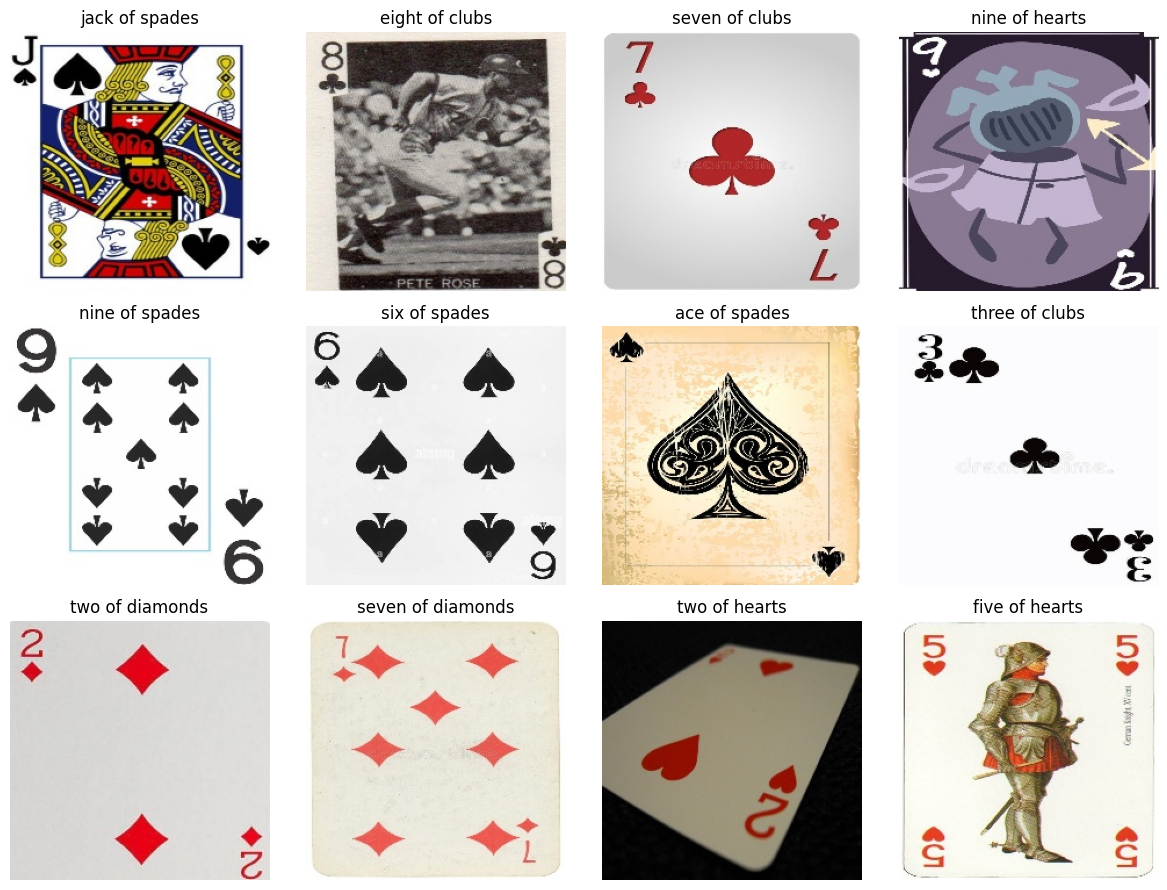

In [3]:
fig, axes = plt.subplots(3, 4, figsize=(12,9))
for ax, name in zip(axes.flat, np.random.default_rng(42).choice(classes, 12, replace=False)):
    file = next(f for f in (root/'train'/name).rglob('*') if f.suffix.lower() in extensions)
    ax.imshow(keras.utils.load_img(file)); ax.set_title(name); ax.axis('off')
plt.tight_layout(); plt.show()

## 3. Підготовка даних
32 × 32; до 12 навчальних, 2 валідаційних і 3 тестових зображень на клас. Це швидкий демонстраційний експеримент.

In [4]:
SIZE = (32, 32)
BATCH = 64
N = len(classes)
rng = np.random.default_rng(42)

def load(split, limit):
    images, labels = [], []
    for i, name in enumerate(classes):
        files = sorted(f for f in (root / split / name).rglob('*') if f.suffix.lower() in extensions)
        for file in rng.choice(files, min(limit, len(files)), replace=False):
            images.append(np.asarray(keras.utils.load_img(file, target_size=SIZE)))
            labels.append(i)
    return np.array(images), np.array(labels)

x_train, y_train = load('train', 12)
x_valid, y_valid = load('valid', 2)
x_test, y_test = load('test', 3)
train = (x_train, y_train)
valid = (x_valid, y_valid)
test = (x_test, y_test)
def early():
    return keras.callbacks.EarlyStopping(patience=1, restore_best_weights=True)
print('Навчальна, валідаційна, тестова:', len(x_train), len(x_valid), len(x_test))
print('GPU:', tf.config.list_physical_devices('GPU'))

Навчальна, валідаційна, тестова: 636 106 159
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 4. CNN та підбір параметрів
Дві швидкості навчання, до двох епох кожна.

In [5]:
def build_cnn(lr):
    model = keras.Sequential([
        layers.Input((*SIZE, 3)), layers.Rescaling(1./255),
        layers.Conv2D(8, 3, activation='relu'), layers.MaxPooling2D(),
        layers.Conv2D(16, 3, activation='relu'), layers.MaxPooling2D(),
        layers.Flatten(), layers.Dense(32, activation='relu'),
        layers.Dense(N, activation='softmax')])
    model.compile(optimizer=keras.optimizers.Adam(lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model
trials = []
for lr in [0.001, 0.003]:
    model = build_cnn(lr)
    h = model.fit(*train, validation_data=valid, batch_size=BATCH, epochs=2, callbacks=[early()])
    trials.append((min(h.history['val_loss']), lr, model, h))
_, lr, cnn, h_cnn = min(trials, key=lambda t: t[0])
display(pd.DataFrame([(t[1], t[0]) for t in trials], columns=['Learning rate', 'Val loss']))

Epoch 1/2
10/10 ━━━━━━━━━━━━━━━━━━━━ 15s 974ms/step - accuracy: 0.0094 - loss: 3.9783 - val_accuracy: 0.0377 - val_loss: 3.9618
Epoch 2/2
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.0346 - loss: 3.9575 - val_accuracy: 0.0566 - val_loss: 3.9532
Epoch 1/2
10/10 ━━━━━━━━━━━━━━━━━━━━ 5s 255ms/step - accuracy: 0.0220 - loss: 3.9773 - val_accuracy: 0.0472 - val_loss: 3.9612
Epoch 2/2
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.0582 - loss: 3.9406 - val_accuracy: 0.0472 - val_loss: 3.9381


,Learning rate,Val loss
0,0.001,3.953160
1,0.003,3.938051


## 5. VGG16: трансферне навчання та донавчання
Ознаки обчислюються один раз. Класифікатор навчається дві епохи, останній згортковий шар — одну епоху на кешованих ознаках.

In [6]:
base = keras.applications.VGG16(weights='imagenet', include_top=False, input_shape=(*SIZE, 3))
# Cache features before the last convolutional layer.
extractor = keras.Model(base.input, base.get_layer('block5_conv2').output)
extractor.trainable = False

def features(x):
    return extractor.predict(keras.applications.vgg16.preprocess_input(x.astype('float32')), batch_size=BATCH, verbose=1)

f_train, f_valid, f_test = [features(x) for x in (x_train, x_valid, x_test)]
last = base.get_layer('block5_conv3')
last.trainable = False
vgg = keras.Sequential([layers.Input(f_train.shape[1:]), last,
    layers.MaxPooling2D(), layers.Flatten(), layers.Dense(N, activation='softmax')])
def compile_vgg(lr):
    vgg.compile(optimizer=keras.optimizers.Adam(lr), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
compile_vgg(0.001)
h_vgg = vgg.fit(f_train, y_train, validation_data=(f_valid, y_valid), batch_size=BATCH, epochs=2, callbacks=[early()])

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 13s 779ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step
Epoch 1/2
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 195ms/step - accuracy: 0.0173 - loss: 45.3361 - val_accuracy: 0.0377 - val_loss: 39.9353
Epoch 2/2
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.0425 - loss: 31.6189 - val_accuracy: 0.0377 - val_loss: 31.2404


In [7]:
last.trainable = True
compile_vgg(0.00001)
h_fine = vgg.fit(f_train, y_train, validation_data=(f_valid, y_valid), batch_size=BATCH, epochs=1, callbacks=[early()])

10/10 ━━━━━━━━━━━━━━━━━━━━ 7s 333ms/step - accuracy: 0.0723 - loss: 26.0941 - val_accuracy: 0.0377 - val_loss: 29.5690


## 6. Криві навчання

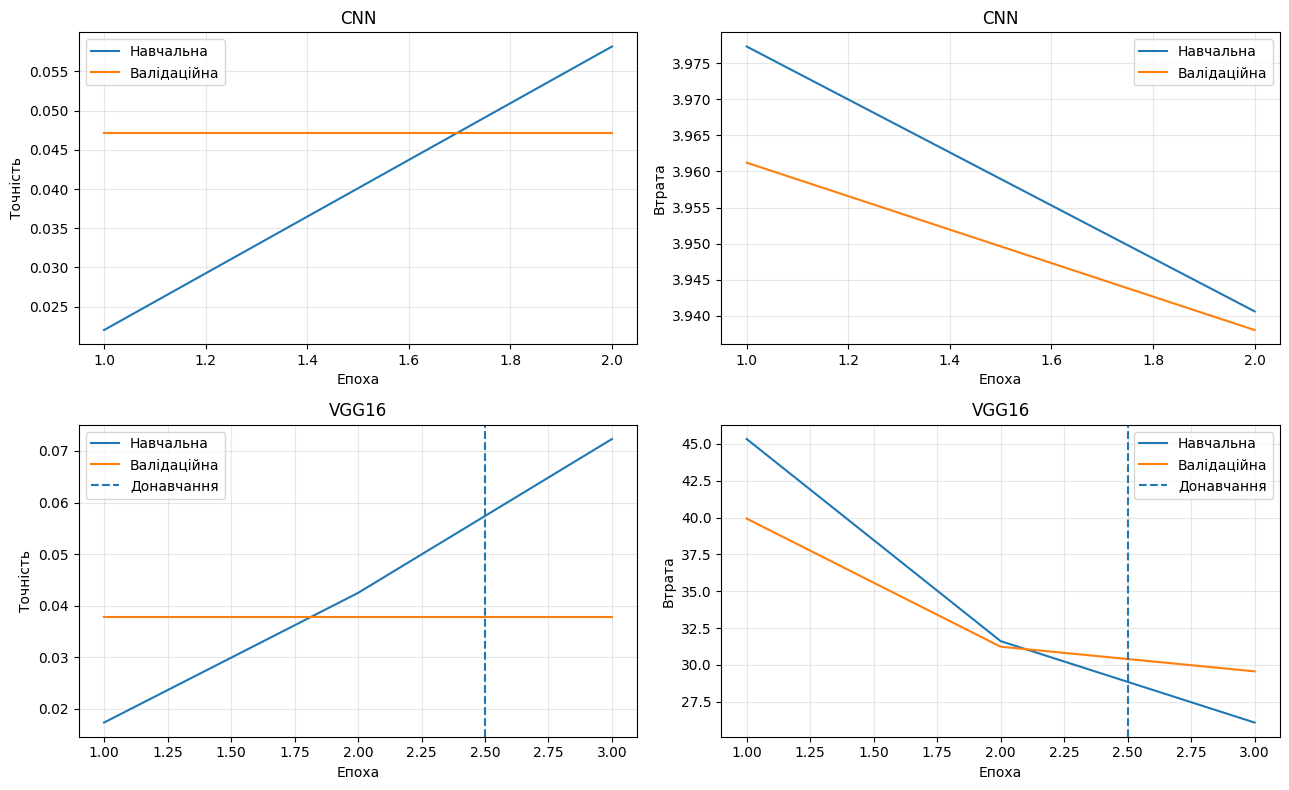

In [8]:
fig, axes = plt.subplots(2,2,figsize=(13,8))
for i, (title, histories) in enumerate([('CNN',[h_cnn]),('VGG16',[h_vgg,h_fine])]):
    for j, metric in enumerate(['accuracy','loss']):
        ax = axes[i,j]
        for key, label in [(metric,'Навчальна'),('val_'+metric,'Валідаційна')]:
            values = sum([h.history[key] for h in histories],[])
            ax.plot(range(1,len(values)+1),values,label=label)
        if len(histories)>1: ax.axvline(len(histories[0].history[metric])+0.5,linestyle='--',label='Донавчання')
        ax.set(title=title,xlabel='Епоха',ylabel='Точність' if metric=='accuracy' else 'Втрата'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 7. Порівняння моделей та оцінювання

,Модель,Валідаційна втрата,Валідаційна точність,Тестова точність,F1 macro
0,CNN,3.938051,0.047170,0.037736,0.010238
1,VGG16,29.569036,0.037736,0.037736,0.028556


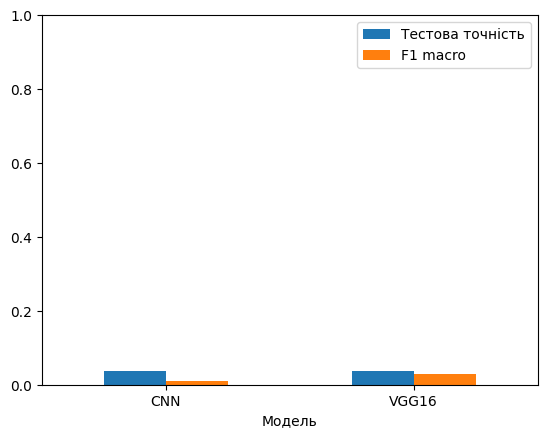

Найкраща модель: CNN


In [9]:
from sklearn.metrics import accuracy_score, f1_score
models = {'CNN': cnn, 'VGG16': vgg}
results = []
for name, model in models.items():
    vx, tx = (x_valid, x_test) if name == 'CNN' else (f_valid, f_test)
    loss, acc = model.evaluate(vx, y_valid, verbose=0)
    pred = model.predict(tx, verbose=0).argmax(axis=1)
    results.append([name, loss, acc, accuracy_score(y_test, pred), f1_score(y_test, pred, average='macro', zero_division=0)])
results = pd.DataFrame(results, columns=['Модель', 'Валідаційна втрата', 'Валідаційна точність', 'Тестова точність', 'F1 macro']).sort_values('Валідаційна втрата')
display(results)
results.set_index('Модель')[['Тестова точність', 'F1 macro']].plot.bar(rot=0, ylim=(0,1))
plt.show()
best_name = results.iloc[0]['Модель']
best = models[best_name]
print('Найкраща модель:', best_name)

## 8. Візуалізація класифікації

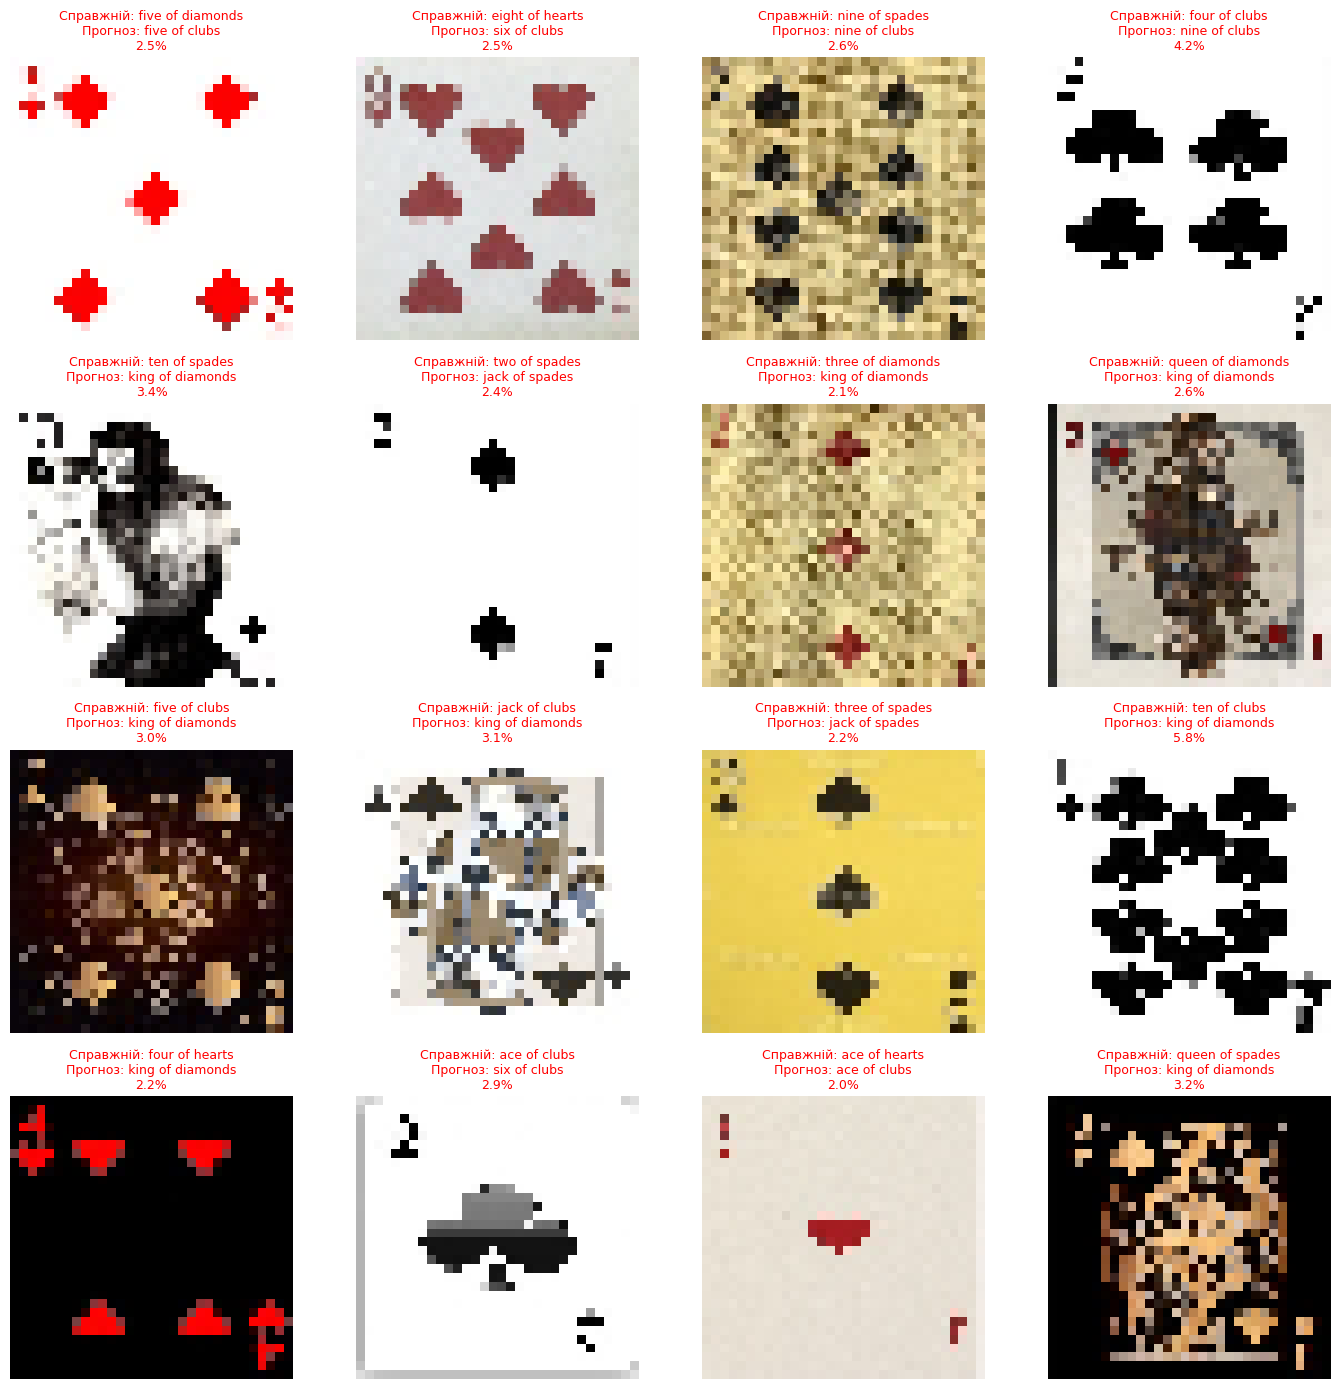

In [10]:
idx = rng.choice(len(x_test), 16, replace=False)
images, labels = x_test[idx], y_test[idx]
probs = best.predict(images if best_name == "CNN" else f_test[idx], verbose=0)
fig, axes = plt.subplots(4,4,figsize=(14,14))
for i,ax in enumerate(axes.flat):
    if i >= len(images): ax.axis('off'); continue
    actual = int(labels[i]); predicted = int(probs[i].argmax())
    ax.imshow(images[i].astype('uint8'))
    ax.set_title(f'Справжній: {classes[actual]}\nПрогноз: {classes[predicted]}\n{probs[i,predicted]:.1%}',color='green' if actual==predicted else 'red',fontsize=9); ax.axis('off')
plt.tight_layout(); plt.show()

## 9. Висновки
У роботі розглянуто класифікацію гральних карт за допомогою CNN та VGG16. Для прискорення експерименту використано зменшену вибірку та кешування ознак VGG16. Виконано підбір швидкості навчання CNN і налаштовано ранню зупинку. Реалізовано донавчання останнього згорткового шару VGG16 та порівняння моделей за точністю і F1-мірою.